# 逻辑回归
逻辑回归就是 线性回归 + sigmoid 函数，将线性回归的值映射到(0,1)之间，从而可以用于分类问题。



## 软件包

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from utils import * # 辅助函数
import copy
import math

## 问题描述

在本练习的这一部分，你将构建一个逻辑回归模型，预测学生是否会被大学录取。

假设你是一所大学某个院系的管理人员，你希望根据申请者两次考试的成绩，确定每位申请者被录取的可能性。 
* 你拥有以往申请者的历史数据，可以将其用作逻辑回归的训练集。 
* 对于每个训练样本，你都拥有申请者两次考试的成绩以及录取决定。 
* 你的任务是构建一个分类模型，根据这两次考试的成绩估计申请者被录取的概率。 

##2.2 加载数据并进行可视化

首先，加载本任务的数据集。 
- 下面展示的 `load_dataset()` 函数将数据加载到变量 `X_train` 和 `y_train` 中
  - `X_train` 包含学生两次考试的成绩
  - `y_train` 是录取决定 
      - 如果学生被录取，则为 `y_train = 1` 
      - 如果学生未被录取，则为 `y_train = 0` 
  - `X_train` 和 `y_train` 都是 numpy 数组。


In [ ]:
X_train, y_train = load_data("data1.txt")

## 激活函数

In [ ]:
def sigmod(z):
    """
    计算 z 的 sigmod 函数
    
    参数：
        z: numpy array

    返回：
        g: numpy array
    """
    return 1.0 / (1.0 + np.exp(-z))

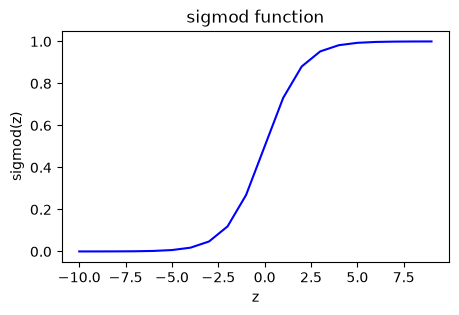

In [ ]:
# 使用 matplotlib 绘制一下这个函数
fig, ax = plt.subplots(1, 1, figsize=(5, 3))
z_temp = np.arange(-10, 10)
y = sigmod(z_temp)
ax.plot(z_temp, y, c="b")
ax.set_xlabel("z")
ax.set_ylabel("sigmod(z)")
ax.set_title("sigmod function")
plt.show()

## 可视化数据
在实现学习算法之前，最好先将数据可视化
我们使用`utils.py`中的`plot_data`函数来可视化数据

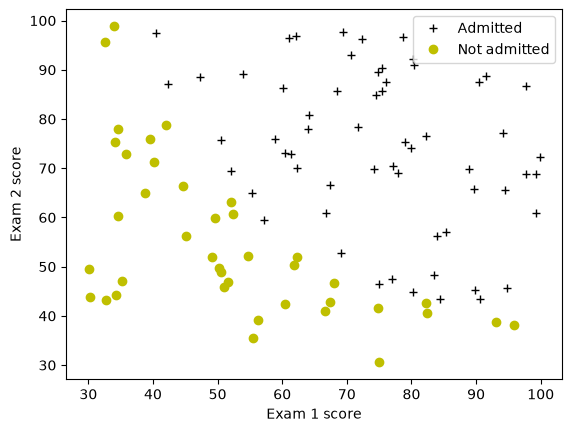

In [ ]:
plot_data(X_train, y_train[:], pos_label="Admitted", neg_label="Not admitted")
plt.ylabel("Exam 2 score")
plt.xlabel("Exam 1 score")
plt.legend(loc="upper right")
plt.show()

## 代价函数


In [ ]:
def compute_cost(X, y, w, b, lambda_ = 1):
    """
    计算所有样本上的代价
    参数：
        X: numpy array, m * n
        y: numpy array, m * 1
        w: numpy array, n * 1
        b: 偏置参数
        lambda_: 正则化参数，现在未使用
    返回：
        total_cost: 代价
    """
    m, n = X.shape
    total_cost = 0

    # np.log 默认底数为 e
    for i in range(m):
        total_cost += -y[i] * np.log(sigmod(np.dot(w.T, X[i]) + b)) - (1 - y[i]) * np.log(1 - sigmod(np.dot(w.T, X[i]) + b))

    return total_cost / m

## 梯度下降
先是计算梯度函数

In [ ]:
def compute_gradient(X, y, w, b, lambda_ = None):
    m, n = X.shape
    dj_dw = np.zeros((w.shape))
    dj_db = 0

    for i in range(m):
        tmp = sigmod(np.dot(X[i], w) + b) - y[i]
        dj_db += tmp;   
        for j in range(n):
            dj_dw[j] += tmp * X[i, j]

    dj_dw = dj_dw / m
    dj_db = dj_db / m

    return dj_dw, dj_db

然后是使用梯度下降学习参数

In [ ]:
def gradient_descent(X, y, w_in, b_in, alpha, num_iters, cost_function, gradient_function, lambda_ = None):
    m, n = X.shape
    J_history = []
    w_history = []

    for i in range(num_iters):
        dj_dw, dj_db = compute_gradient(X, y, w_in, b_in, lambda_)
        w_in = w_in - alpha * dj_dw
        b_in = b_in - alpha * dj_db
        if i < 100000:
            cost = cost_function(X, y, w_in, b_in, lambda_)
            J_history.append(cost)
        if i % math.ceil(num_iters / 10) == 0 or i == num_iters - 1:
            w_history.append(copy.deepcopy(w_in))
            print(f"Iteration {i:4d}: Cost {cost.item():.8f}")

    return w_in, b_in, J_history, w_history

In [10]:
# 运行梯度下降算法，学习适用于我们的数据集的参数
np.random.seed(1)
initial_w = 0.01 * (np.random.rand(2).reshape(-1,1) - 0.5)
initial_b = -8

iterations = 10000
alpha = 0.001

w, b, J_history, w_history = gradient_descent(X_train, y_train, initial_w, initial_b, alpha, iterations, compute_cost, compute_gradient)

Iteration    0: Cost 0.96379018
Iteration 1000: Cost 0.30509033
Iteration 2000: Cost 0.30472281
Iteration 3000: Cost 0.30435771
Iteration 4000: Cost 0.30399500
Iteration 5000: Cost 0.30363467
Iteration 6000: Cost 0.30327668
Iteration 7000: Cost 0.30292101
Iteration 8000: Cost 0.30256764
Iteration 9000: Cost 0.30221655
Iteration 9999: Cost 0.30186807


## 绘制决策边界
现在，我们将使用最终参数来绘制线性拟合结果
使用 utils.py 中的 plot_decision_boundary 函数

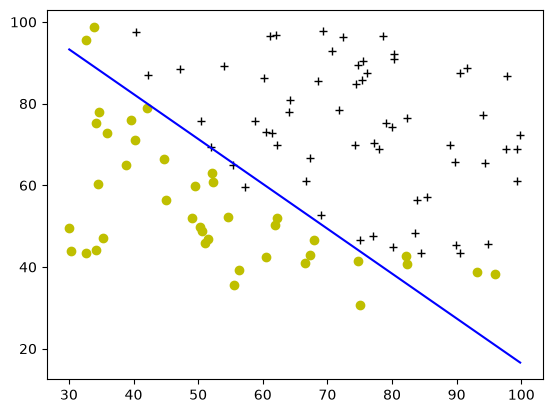

In [11]:
plot_decision_boundary(w, b, X_train, y_train)

## 评估逻辑回归
可以通过查看学得的模型在训练集上的预测效果，来评估找到的参数的质量


请完成 `predict` 函数，根据给定的数据集以及学得的参数向量 $w$ 和 $b$，生成 `1` 或 `0` 的预测结果。
- 首先，你需要为每个样本计算模型的预测值 $f(x^{(i)}) = g(w \cdot x^{(i)})$ 
- 我们将模型的输出（$f(x^{(i)})$）解释为给定 $x^{(i)}$、以 $w$ 为参数时 $y^{(i)}=1$ 的概率。
- 因此，要从逻辑回归模型得到最终预测（$y^{(i)}=0$ 或 $y^{(i)}=1$），你可以使用以下启发式规则——

  如果 $f(x^{(i)}) >= 0.5$，则预测为 $y^{(i)}=1$
  
  如果 $f(x^{(i)}) < 0.5$，则预测为 $y^{(i)}=0$


In [18]:
def predict(X, w, b):
    """
    返回 p ndarray (m,1)，使用 0.5 作为阈值对 X 得到的预测结果
    """
    m, n = X.shape
    p = np.zeros(m)

    for i in range(m):
        p[i] = int(sigmod(np.dot(w.T, X[i]) + b).item() >= 0.5)

    return p



In [19]:
# 测试你的 predict 代码
np.random.seed(1)
tmp_w = np.random.randn(2)
tmp_b = 0.3    
tmp_X = np.random.randn(4, 2) - 0.5

tmp_p = predict(tmp_X, tmp_w, tmp_b)
print(f'Output of predict: shape {tmp_p.shape}, value {tmp_p}')

Output of predict: shape (4,), value [0. 1. 1. 1.]


现在我们来用它计算训练集上的准确率

In [20]:
p = predict(X_train, w, b)
print(f'Train accuracy: {np.mean(p == y_train) * 100}%')

Train accuracy: 92.0%
